In [21]:
# Imports and Paths

import pandas as pd
from pathlib import Path
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

project_root = Path.cwd().parent
data_dir = project_root / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
figures_dir = project_root / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

In [22]:
# Setup and load

sns.set(style="whitegrid")

data_path = data_dir / "processed" / "cisplatin_rnaseq_modelready_clean.csv"
df = pd.read_csv(data_path)

df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
0,SIDM01132,Cisplatin,3.168266,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0,...,6.17065,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,3.47415,4.0301
1,SIDM00848,Cisplatin,-0.007561,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0,...,7.09150,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,3.60640,4.5211
2,SIDM00269,Cisplatin,0.045420,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0,...,4.53920,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,4.93400,5.4561
3,SIDM00203,Cisplatin,0.923136,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0,...,6.45100,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,4.35900,5.3366
4,SIDM01111,Cisplatin,-0.134330,4.49250,2.8115,0.0144,0.47510,0.0286,0.5558,0.0,...,7.37920,1.28690,2.26000,4.94810,2.7634,0.0,3.20950,3.99550,4.02240,4.9635


In [23]:
# Define columns:

model_col = "model_id"
drug_col = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

X = df[feature_cols].values
y = df[response_col].values

X.shape, y.shape

((743, 36438), (743,))

In [24]:
#  Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((594, 36438), (149, 36438))

In [25]:
# Final models to compare

ridge_a100 = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Ridge(alpha=100, random_state=42)
)

ridge_a10000 = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Ridge(alpha=10000, random_state=42)
)

rf3 = make_pipeline(
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=7,
        max_features=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
)

ridge_a100.fit(X_train, y_train)
ridge_a10000.fit(X_train, y_train)
rf3.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36438
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a C

In [26]:
# Define metrics function

def regression_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

In [27]:
# Build the metrics table

def get_metrics(name, model):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    r2_train, rmse_train, mae_train = regression_metrics(y_train, y_train_pred)
    r2_test, rmse_test, mae_test = regression_metrics(y_test, y_test_pred)
    return {
        "model": name,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "mae_train": mae_train,
        "mae_test": mae_test
    }

rows = [
    get_metrics("Ridge_a100", ridge_a100),
    get_metrics("Ridge_a10000", ridge_a10000),
    get_metrics("RF3", rf3),
]

metrics_df = pd.DataFrame(rows)
metrics_df

,model,r2_train,r2_test,rmse_train,rmse_test,mae_train,mae_test
0,Ridge_a100,0.999973,0.316966,0.009482,1.555581,0.006265,1.231734
1,Ridge_a10000,0.932001,0.339243,0.477268,1.530003,0.353436,1.222917
2,RF3,0.763324,0.278231,0.890410,1.599081,0.684064,1.267344


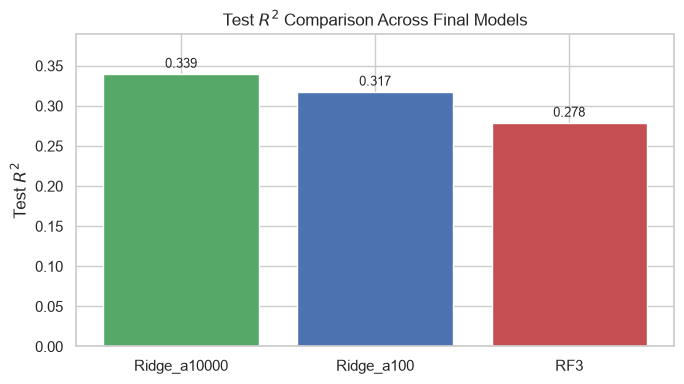

In [28]:
# Bar chart of test R^2 values

plot_df = metrics_df.sort_values("r2_test", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(plot_df["model"], plot_df["r2_test"], color=["#55A868", "#4C72B0", "#C44E52"])

ax.set_ylabel("Test $R^2$")
ax.set_title("Test $R^2$ Comparison Across Final Models")
ax.set_ylim(0, plot_df["r2_test"].max() + 0.05)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.005, f"{height:.3f}",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "model_test_r2_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

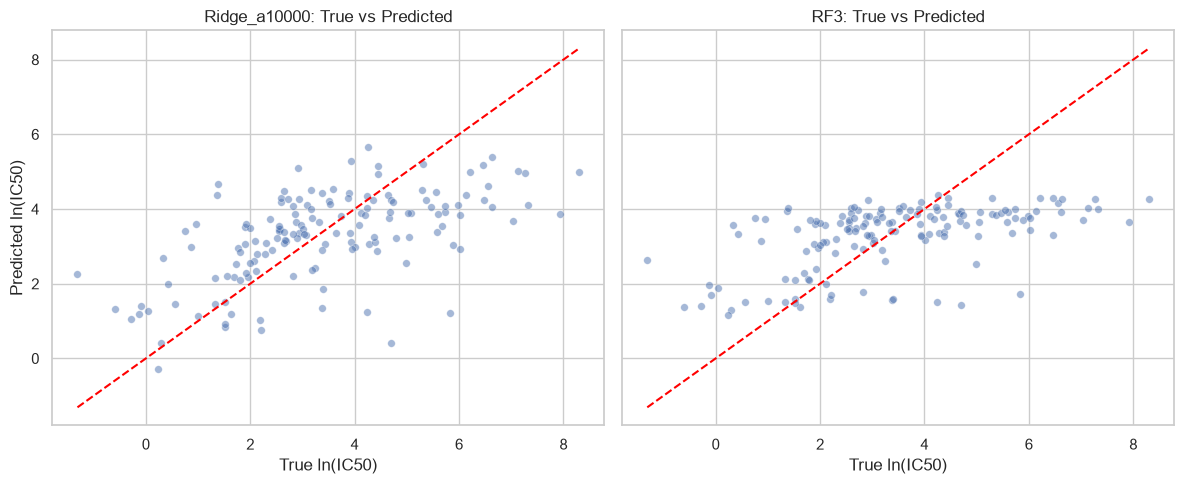

In [29]:
# Predicted vs true plots

# Get predictions
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Build a small plotting dataframe
plot_df = pd.DataFrame({
    "true": y_test, # Actual values from data
    "Ridge_a10000": ridge_preds,
    "RF3": rf3_preds
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Common limits so both plots use the same scale
min_val = min(plot_df["true"].min(), plot_df["Ridge_a10000"].min(), plot_df["RF3"].min())
max_val = max(plot_df["true"].max(), plot_df["Ridge_a10000"].max(), plot_df["RF3"].max())

# Ridge plot
sns.scatterplot(
    x="true",
    y="Ridge_a10000",
    data=plot_df,
    alpha=0.5,
    s=30,
    ax=axes[0]
)
axes[0].plot([min_val, max_val], [min_val, max_val], "--", color="red")
axes[0].set_title("Ridge_a10000: True vs Predicted")
axes[0].set_xlabel("True ln(IC50)")
axes[0].set_ylabel("Predicted ln(IC50)")

# RF plot
sns.scatterplot(
    x="true",
    y="RF3",
    data=plot_df,
    alpha=0.5,
    s=30,
    ax=axes[1]
)
axes[1].plot([min_val, max_val], [min_val, max_val], "--", color="red")
axes[1].set_title("RF3: True vs Predicted")
axes[1].set_xlabel("True ln(IC50)")
axes[1].set_ylabel("Predicted ln(IC50)")

plt.tight_layout()
plt.savefig(figures_dir / "predicted_vs_true_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

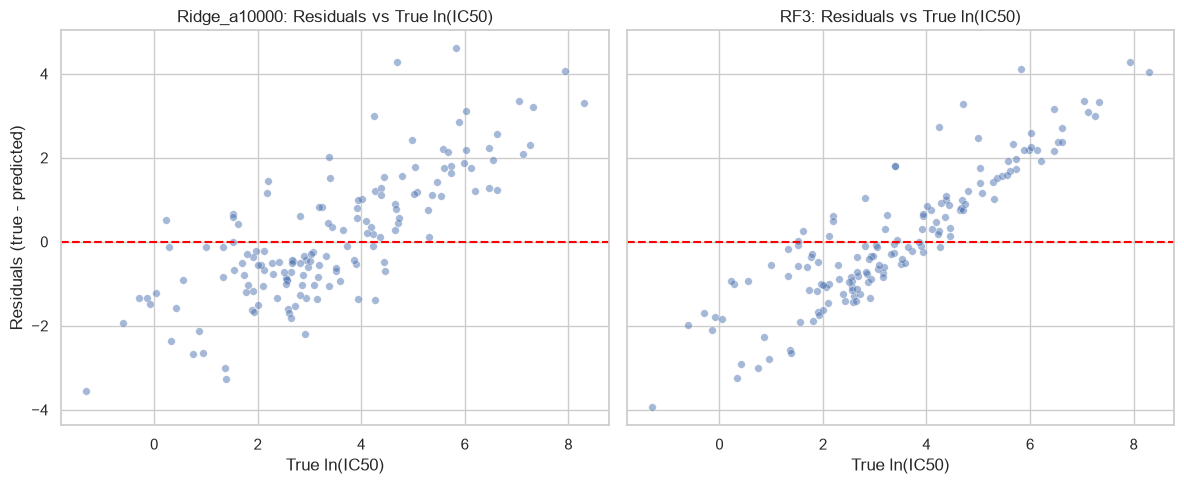

In [30]:
# Residuals vs true plots

# Predictions on the test set
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Residuals = true - predicted
ridge_resid = y_test - ridge_preds
rf3_resid = y_test - rf3_preds

# Data for plotting
resid_df = pd.DataFrame({
    "true": y_test,
    "Ridge_a10000_resid": ridge_resid,
    "RF3_resid": rf3_resid
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Ridge residual plot
sns.scatterplot(
    x="true",
    y="Ridge_a10000_resid",
    data=resid_df,
    alpha=0.5,
    s=30,
    ax=axes[0]
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Ridge_a10000: Residuals vs True ln(IC50)")
axes[0].set_xlabel("True ln(IC50)")
axes[0].set_ylabel("Residuals (true - predicted)")

# RF residual plot
sns.scatterplot(
    x="true",
    y="RF3_resid",
    data=resid_df,
    alpha=0.5,
    s=30,
    ax=axes[1]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("RF3: Residuals vs True ln(IC50)")
axes[1].set_xlabel("True ln(IC50)")
axes[1].set_ylabel("Residuals (true - predicted)")

plt.tight_layout()
plt.savefig(figures_dir / "residuals_vs_true_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

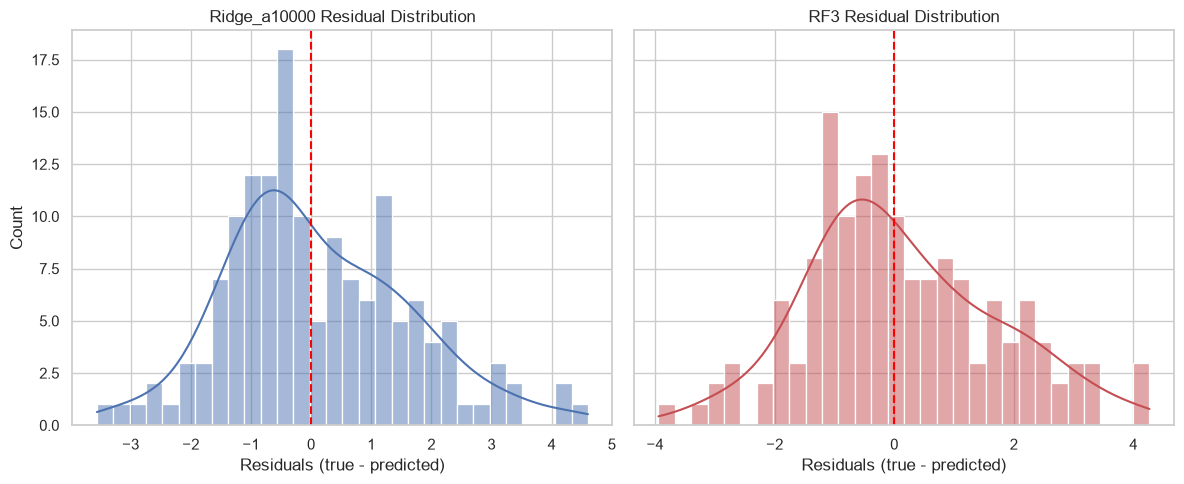

In [31]:
# Residual distribution histograms

# Predictions on the test set
ridge_preds = ridge_a10000.predict(X_test)
rf3_preds = rf3.predict(X_test)

# Residuals = true - predicted
ridge_resid = y_test - ridge_preds
rf3_resid = y_test - rf3_preds

resid_df = pd.DataFrame({
    "Ridge_a10000_resid": ridge_resid,
    "RF3_resid": rf3_resid
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

sns.histplot(resid_df["Ridge_a10000_resid"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Ridge_a10000 Residual Distribution")
axes[0].set_xlabel("Residuals (true - predicted)")
axes[0].set_ylabel("Count")

sns.histplot(resid_df["RF3_resid"], bins=30, kde=True, ax=axes[1], color="#C44E52")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("RF3 Residual Distribution")
axes[1].set_xlabel("Residuals (true - predicted)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig(figures_dir / "residual_distribution_ridge_rf.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

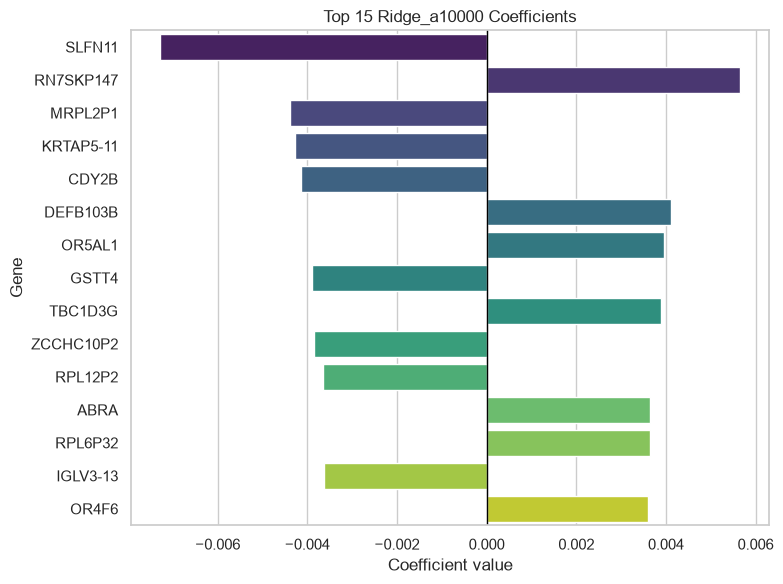

In [32]:
# Ridge feature importance/coefficient plot

gene_names = df.drop(columns=["model_id", "drug_name", "ln_ic50"]).columns # Same as feature_cols from earlier

coef_df = pd.DataFrame({
    "gene": gene_names,
    "coef": ridge_a10000.named_steps["ridge"].coef_
})

# Sort coefficients by absolute value highest to lowest, keep top (top_n) values
top_n = 15
top_coef_df = coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index).head(top_n)

plt.figure(figsize=(8, 6))
sns.barplot(data=top_coef_df, x="coef", y="gene", palette="viridis", hue="gene", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.title(f"Top {top_n} Ridge_a10000 Coefficients")
plt.xlabel("Coefficient value")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig(figures_dir / "ridge_a10000_top_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

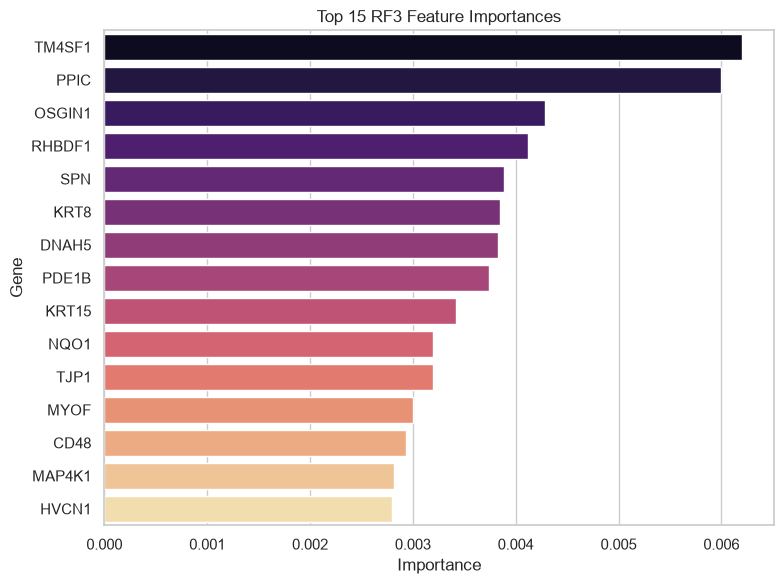

In [33]:
# RF3 feature importance/coefficient plot

gene_names = df.drop(columns=["model_id", "drug_name", "ln_ic50"]).columns

rf_importance_df = pd.DataFrame({
    "gene": gene_names,
    "importance": rf3.named_steps["randomforestregressor"].feature_importances_
})

top_n = 15
top_rf_df = rf_importance_df.sort_values("importance", ascending=False).head(top_n)

plt.figure(figsize=(8, 6))
sns.barplot(data=top_rf_df, x="importance", y="gene", palette="magma", hue="gene", legend=False)
plt.title(f"Top {top_n} RF3 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig(figures_dir / "rf3_top_feature_importances.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

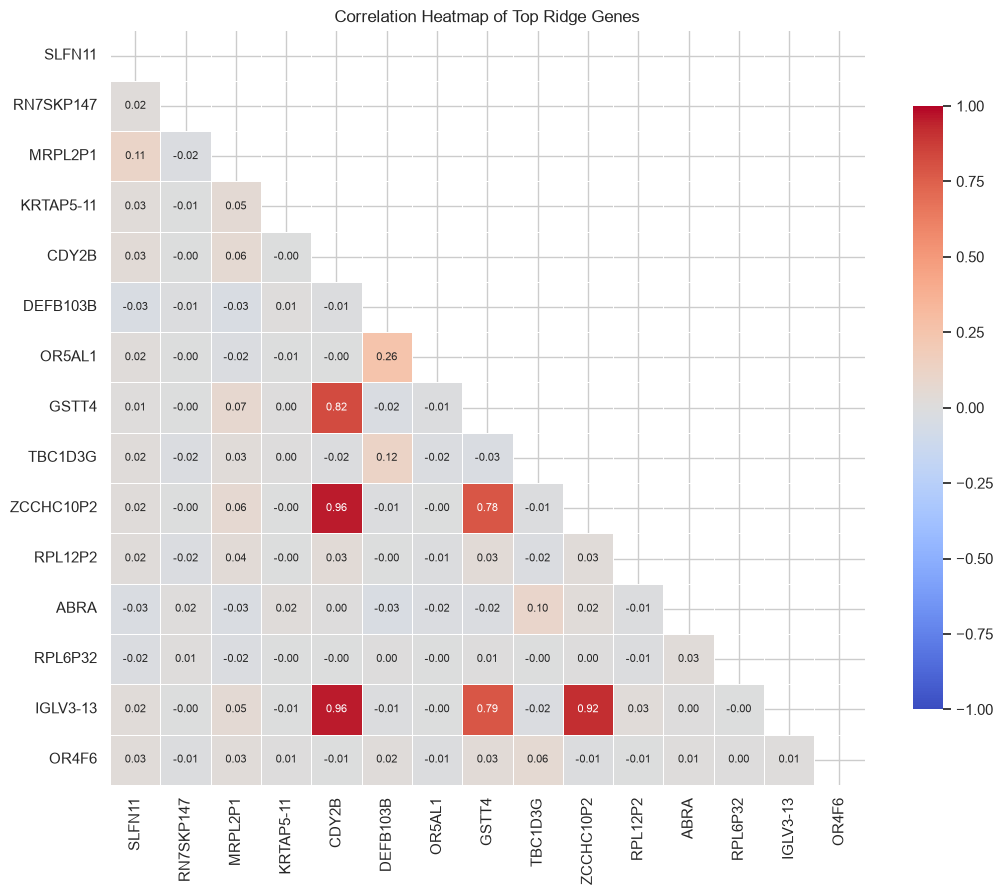

In [34]:
# Correlation heatmap of top genes

# Sort top genes by absolute Ridge coefficient, then get their names
top_genes_sorted = (
    coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index)
    .head(15)["gene"]
    .tolist()
)

gene_df = df[top_genes_sorted]
corr = gene_df.corr()

# Mask upper triangle (would be duplicate of lower triangle)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8},
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap of Top Ridge Genes")
plt.tight_layout()
plt.savefig(figures_dir / "top_gene_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [35]:
# Saves objects so Notebook 5 can reload it without training

save_dir = data_dir / "notebook_artifacts"
save_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(X_train, save_dir / "X_train.pkl")
joblib.dump(X_test, save_dir / "X_test.pkl")
joblib.dump(y_train, save_dir / "y_train.pkl")
joblib.dump(y_test, save_dir / "y_test.pkl")

joblib.dump(ridge_a10000, save_dir / "ridge_a10000.pkl")
joblib.dump(rf3, save_dir / "rf3.pkl")

joblib.dump(feature_cols, save_dir / "feature_names.pkl")

['C:\\Users\\draar\\gdsc-drug-response-project\\data\\notebook_artifacts\\feature_names.pkl']